# IMDb: modelos, erros e steering

Nestor, Letícia e Gabriel. Notebook de leitura e verificação dos resultados salvos. As células de treino são opcionais para evitar repetir uma execução longa. O código PyTorch está em `src/imdb_lab/`.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.json').exists())
sys.path.insert(0, str(ROOT / 'src'))
def read(p): return json.loads((ROOT / p).read_text())
def plot(name): display(Image(filename=str(ROOT / 'results' / 'figures' / name)))
manifest = read('data/manifest.json')
pd.DataFrame({k: {'n': v['n'], **v['label_counts']} for k,v in manifest['splits'].items()}).T

,n,1,0
train,19823,9954,9869
validation,2478,1245,1233
calibration,2478,1244,1234
test,25000,12500,12500


## Integridade dos dados

Teste oficial preservado; duplicações textuais removidas do treino. A validação escolhe modelos; uma divisão adicional calibra probabilidades. Não existe classe neutra nesta base.

In [2]:
display(manifest['audit'])
frames = {s: pd.read_parquet(ROOT / 'data' / f'{s}.parquet') for s in manifest['splits']}
for a in frames:
    for b in frames:
        if a != b: assert not set(frames[a].text_sha256) & set(frames[b].text_sha256)
assert len(frames['test']) == 25000
print('Divisões sem sobreposição textual; teste com 25.000 avaliações.')

{'official_train_n': 25000,
 'official_test_n': 25000,
 'train_rows_matching_test_text': 123,
 'conflicting_train_rows_excluded': 0,
 'duplicate_train_rows_excluded': 98,
 'retained_train_pool_n': 24779,
 'duplicate_test_rows_retained': 201,
 'test_policy': 'Original test retained. Training duplicates removed using test text hashes only.'}

Divisões sem sobreposição textual; teste com 25.000 avaliações.


## Modelos

Referência: TF-IDF + regressão logística. CNN PyTorch: embeddings aprendidos + filtros 3/4/5 + pooling mascarado. BERT-base: ajuste integral dos pesos. Vocabulários e pesos usam apenas treino. Compare os orçamentos de entrada, o hardware e a seleção de hiperparâmetros nos metadados.

In [3]:
from imdb_lab.models import TextCNN
import inspect
print(inspect.getsource(TextCNN))
for m in ['tfidf','cnn','bert']:
    meta = read(f'results/{m}/metadata.json')
    print(m, 'parâmetros ajustados:', meta['trainable_parameters'], 'tempo de treino (min):', round(meta['training_seconds']/60,2))

class TextCNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, filters=100, kernels=(3, 4, 5), dropout=.5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.convs = nn.ModuleList(nn.Conv1d(embedding_dim, filters, k) for k in kernels)
        self.kernels = tuple(kernels)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(filters * len(kernels), 2)

    def forward(self, input_ids, lengths):
        x = self.embedding(input_ids).transpose(1, 2)
        pooled = []
        for conv, k in zip(self.convs, self.kernels):
            features = torch.relu(conv(x))
            # Padded convolution windows must never win max pooling.
            n_valid = (lengths - k + 1).clamp_min(1)
            keep = torch.arange(features.shape[-1], device=features.device)[None, :] < n_valid[:, None]
            features = features.masked_fill(~keep[:, None, :], torch.finfo(features.dtype).mi

,model,split,probabilities,n,accuracy,f1_macro,log_loss,brier,roc_auc,ece_10,tn,fp,fn,tp,false_positive_rate,false_negative_rate
7,bert,test,calibrated,25000,0.90944,0.909414,0.227835,0.067006,0.969948,0.015498,11158,1342,922,11578,0.10736,0.07376
15,cnn,test,calibrated,25000,0.86784,0.867817,0.303703,0.094048,0.943572,0.006554,10682,1818,1486,11014,0.14544,0.11888
23,tfidf,test,calibrated,25000,0.90144,0.901440,0.239638,0.072067,0.964922,0.005860,11266,1234,1230,11270,0.09872,0.09840


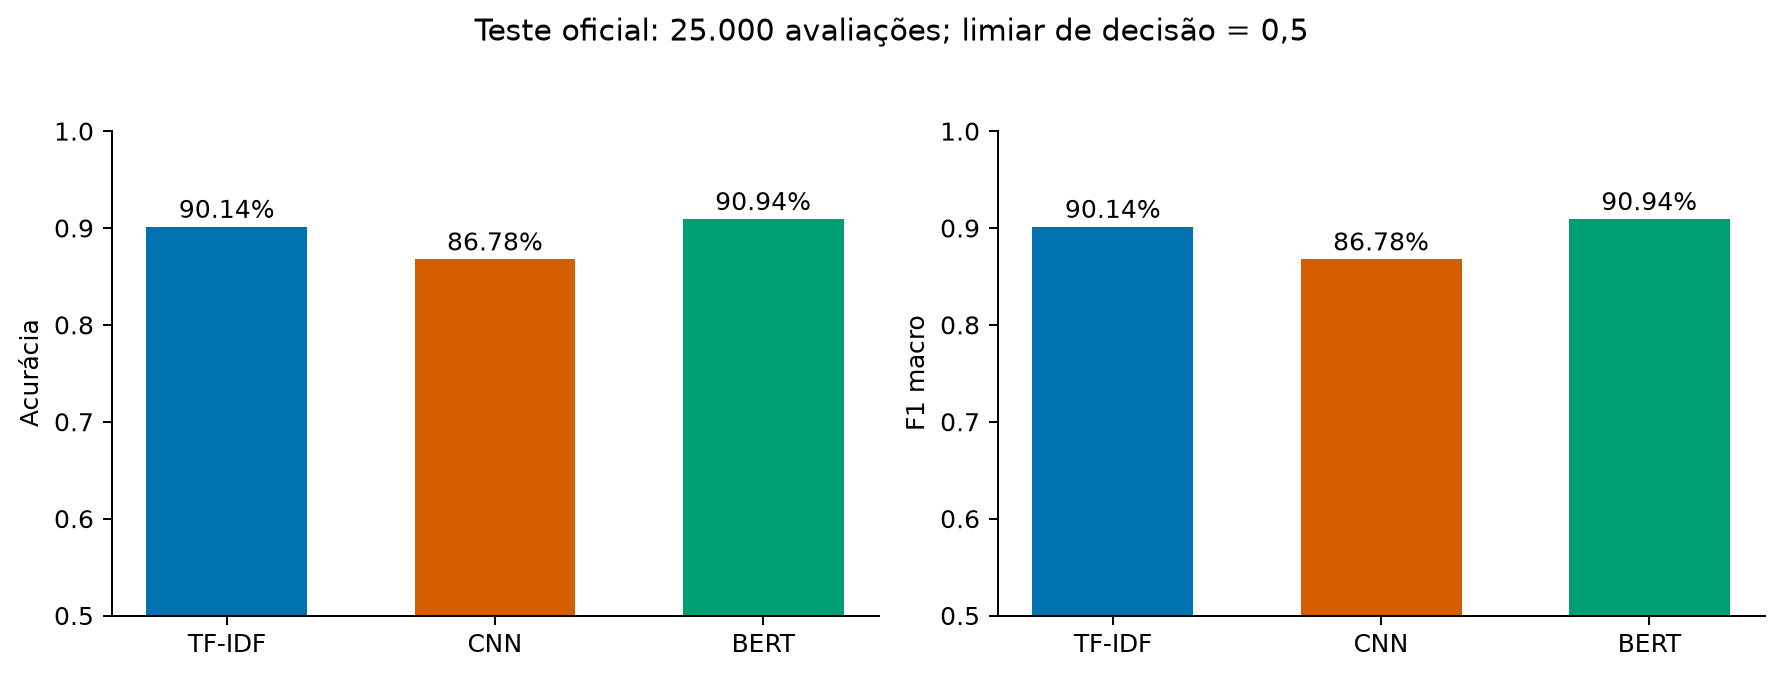

In [4]:
comparison = pd.read_csv(ROOT / 'results/comparison.csv')
display(comparison.loc[(comparison.split=='test') & (comparison.probabilities=='calibrated')])
plot('model_comparison.png')

In [5]:
display(read('results/findings.json'))

{'comparison': 'Maior F1 macro observado no teste: BERT-base ajustado (90.94%). Diferença de acurácia BERT menos TF-IDF: +0.80 pontos percentuais. Uma execução por modelo, com limites de entrada diferentes.',
 'length': 'BERT: acurácia de 93.10% até 100 palavras e 82.60% acima de 500. Associação descritiva; não identifica isoladamente o efeito do truncamento.',
 'steering': 'RFM, 256 exemplos de teste: P(positivo) média bruta em alfa -4 / 0 / +4 = 0.480 / 0.511 / 0.540. Nos cinco controles aleatórios, médias em -4 / +4 = 0.509 / 0.513. Texto idêntico; probabilidades sob intervenção não têm calibração validada.',
 'editing': 'Edição RFM em cinco sondas sintéticas: média de P(positivo) do juiz TF-IDF sem hooks em alfa -4 / 0 / +4 = 0.416 / 0.453 / 0.674. Diagnóstico de escores, não avaliação humana nem benchmark de reescrita.'}

## Calibração e custo

Uma temperatura por modelo é ajustada no conjunto de calibração. Seu ajuste não usa teste e não altera as decisões no limiar 0,5. ECE depende da discretização escolhida.

,model,split,probabilities,accuracy,f1_macro,log_loss,ece_10
0,bert,train,raw,0.963174,0.963167,0.113837,0.009548
1,bert,train,calibrated,0.963174,0.963167,0.128695,0.036631
2,bert,validation,raw,0.912833,0.912803,0.240394,0.037053
3,bert,validation,calibrated,0.912833,0.912803,0.225313,0.015747
4,bert,calibration,raw,0.907183,0.907148,0.252881,0.041373
5,bert,calibration,calibrated,0.907183,0.907148,0.234122,0.015911
6,bert,test,raw,0.909440,0.909414,0.243301,0.036580
7,bert,test,calibrated,0.909440,0.909414,0.227835,0.015498
8,cnn,train,raw,0.949453,0.949448,0.156665,0.049353
9,cnn,train,calibrated,0.949453,0.949448,0.162098,0.055735


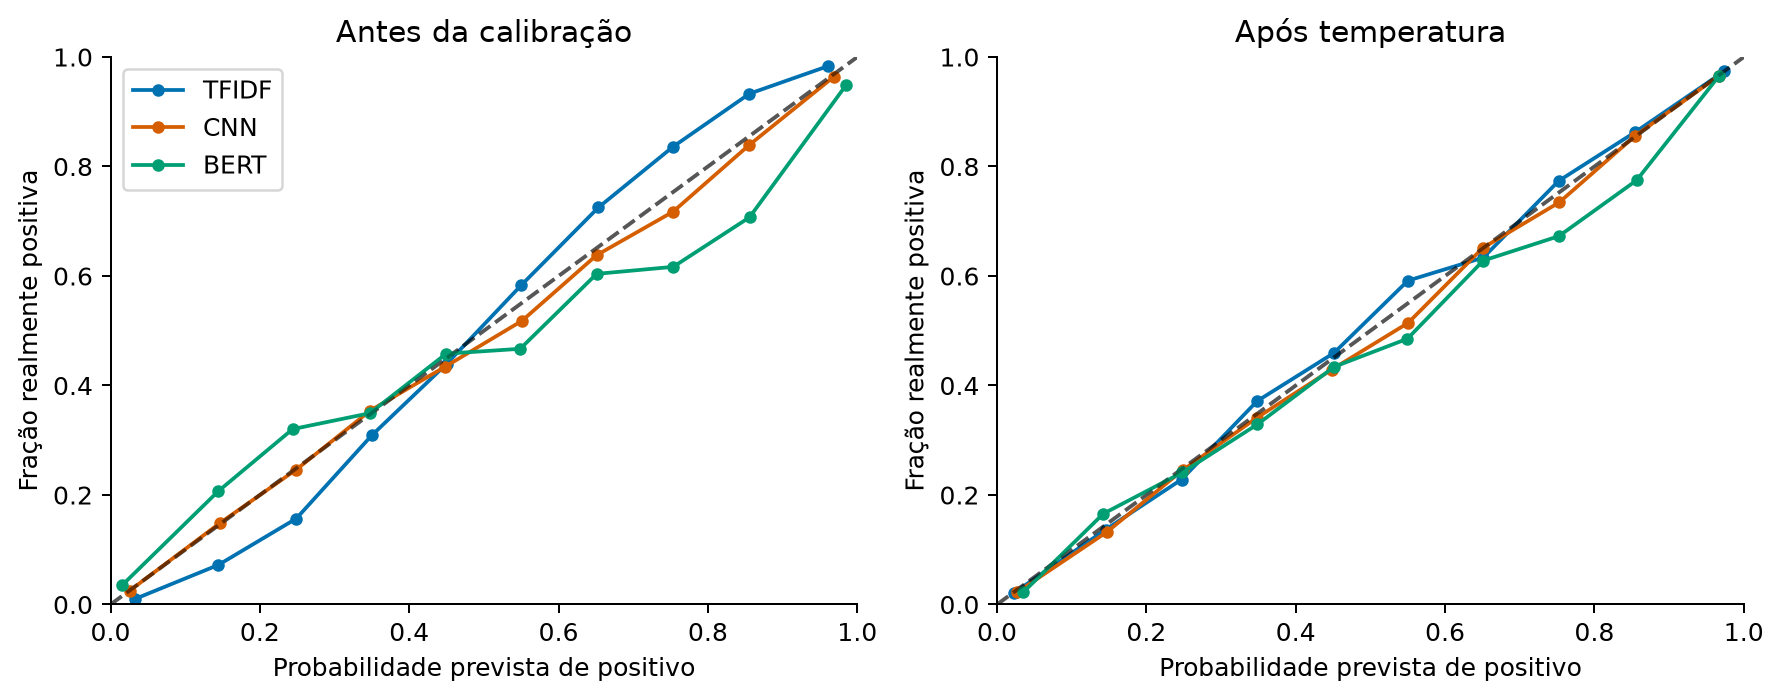

In [6]:
display(comparison[['model','split','probabilities','accuracy','f1_macro','log_loss','ece_10']])
plot('calibration.png')

## Falsos positivos e falsos negativos

Classe positiva = avaliação positiva. FP: negativo → positivo. FN: positivo → negativo. As análises comparam FP a TN e FN a TP, mantendo o rótulo real fixo.

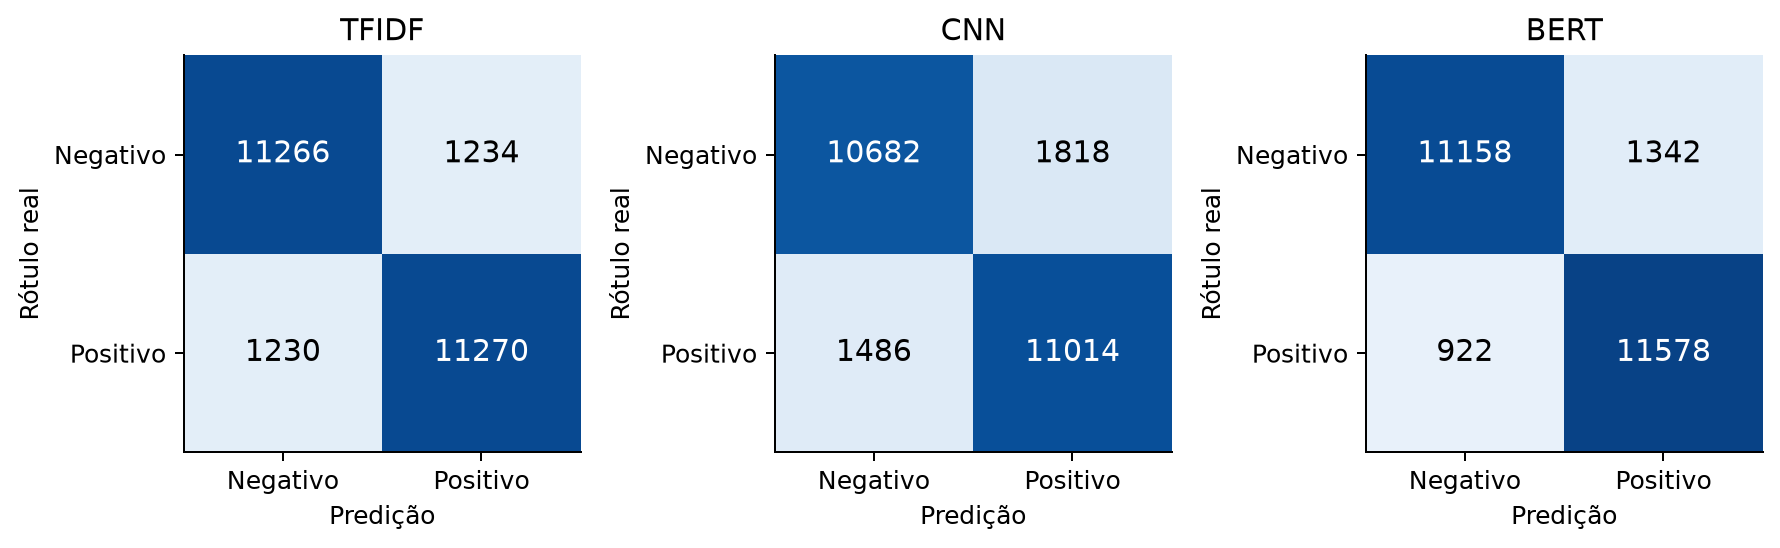

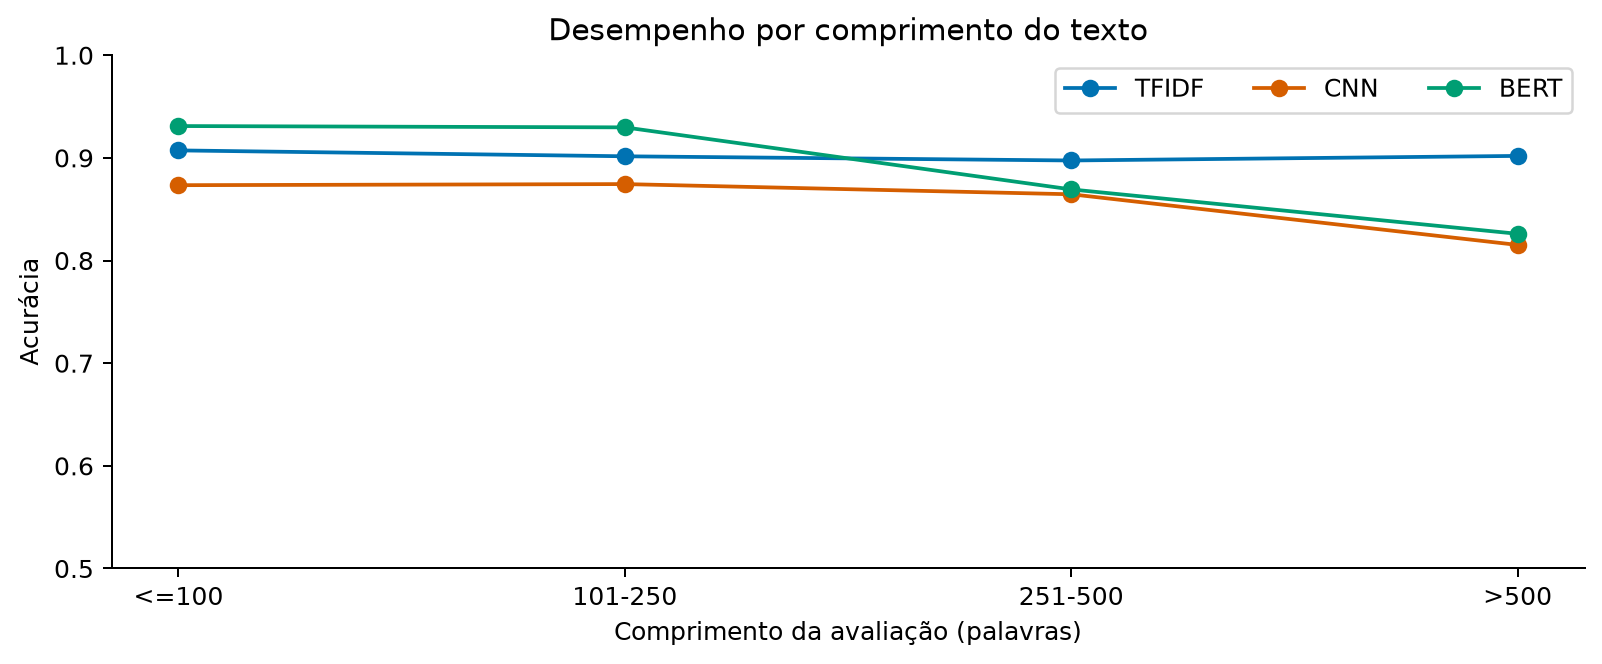

,model,id,outcome,p_positive,word_count,text
0,tfidf,imdb_test_06245,FP,0.999664,404,Mickey Rourke hunts Diane Lane in Elmore Leona...
1,tfidf,imdb_test_04118,FP,0.999047,60,This is definitely one of the best Kung fu mov...
2,tfidf,imdb_test_12061,FP,0.998709,79,This movie was pure genius. John Waters is bri...
3,tfidf,imdb_test_11783,FP,0.753888,216,In this follow up to The Naked Civil Servant w...
4,tfidf,imdb_test_06087,FP,0.559778,321,I expected so much more than what I received f...
5,tfidf,imdb_test_02654,FP,0.886813,35,"The screen-play is very bad, but there are som..."
6,tfidf,imdb_test_20621,FN,0.000759,213,This was Laurel and Hardy's last silent film f...
7,tfidf,imdb_test_24001,FN,0.001003,106,Simon Wests pg-13 thriller about a babysitter ...
8,tfidf,imdb_test_15208,FN,0.002552,347,**SPOILERS AHEAD** It is really unfortunate th...
9,tfidf,imdb_test_16907,FN,0.449345,167,I've been a fan of Rachael's since the beginni...


{'_provenance': 'Leitura qualitativa pelo assistente. Hipóteses interpretativas; não constitui anotação nem avaliação por revisores humanos independentes.',
 'tfidf:imdb_test_06245': 'O texto recomenda Killshot e contém elogios diretos, além de elogios a outros filmes. O rótulo oficial negativo contrasta com essa leitura. É um rótulo discutível, não uma demonstração clara de falha semântica do classificador; o rótulo é preservado.',
 'tfidf:imdb_test_20621': 'A avaliação rotulada positiva contém críticas explícitas: worst part, contrived and pointless, unconvincing e ended with a whimper. Há elogios pontuais a Laurel e Hardy. O escore negativo acompanha boa parte do conteúdo textual, mostrando a ambiguidade entre o tom do texto e seu rótulo agregado.',
 'cnn:imdb_test_04118': 'O texto curto elogia o filme como um dos melhores do gênero e chama a luta final de masterpiece, mas seu rótulo oficial é negativo. A predição positiva parece compatível com a leitura; pode haver ruído ou inconsi

In [7]:
plot('confusion_matrices.png')
plot('length_performance.png')
examples = read('results/analysis/error_examples.json')
display(pd.DataFrame(examples)[['model','id','outcome','p_positive','word_count','text']])
review_path = ROOT/'results/analysis/qualitative_review.json'
if review_path.exists(): display(json.loads(review_path.read_text()))

## Segmentação semântica

Clusters aprendidos em amostra do treino sem rótulos, com encoder independente. Frequências e marcadores são exploratórios, sobrepostos e não causais. A tabela inclui tamanhos e intervalos de Wilson.

{'0': ['disney',
  'animation',
  'animated',
  'cartoon',
  'original',
  'characters',
  'like',
  'muppet',
  'kids',
  'story'],
 '1': ['man',
  'police',
  'murder',
  'brother',
  'kill',
  'wife',
  'father',
  'killer',
  'cop',
  'gets'],
 '2': ['movie',
  'funny',
  'comedy',
  'jokes',
  'humor',
  'actor',
  'rock',
  'chris',
  'unfunny',
  'worst'],
 '3': ['film',
  'war',
  'documentary',
  'people',
  'history',
  'american',
  'world',
  'footage',
  'art',
  'political'],
 '4': ['love',
  'woman',
  'young',
  'emma',
  'actress',
  'musical',
  'jane',
  'romantic',
  'film',
  'austen'],
 '5': ['horror',
  'zombie',
  'zombies',
  'movie',
  'gore',
  'bad',
  'horror movie',
  'just',
  'slasher',
  'movies'],
 '6': ['series',
  'episode',
  'season',
  'episodes',
  'shows',
  'match',
  'tv',
  'pilot',
  'betty',
  'like'],
 '7': ['movie',
  'bad',
  'good',
  'acting',
  'movies',
  'film',
  'really',
  'watch',
  'just',
  'story']}

,model,group,value,n,accuracy,f1_macro,log_loss,brier,roc_auc,ece_10,...,fp,fn,tp,false_positive_rate,false_negative_rate,fpr_ci_low,fpr_ci_high,fnr_ci_low,fnr_ci_high,small_group
4,tfidf,semantic_cluster,0,1805,0.908587,0.907627,0.239894,0.067715,0.963760,0.019314,...,89,76,912,0.108935,0.076923,0.089373,0.132158,0.061897,0.095226,False
5,tfidf,semantic_cluster,1,3323,0.865483,0.865069,0.300587,0.092482,0.944751,0.015885,...,225,222,1530,0.143221,0.126712,0.126768,0.161414,0.111948,0.143110,False
6,tfidf,semantic_cluster,2,3063,0.905975,0.904944,0.232878,0.069941,0.966576,0.009388,...,148,140,1228,0.087316,0.102339,0.074792,0.101705,0.087375,0.119531,False
7,tfidf,semantic_cluster,3,3690,0.896206,0.890992,0.256087,0.077593,0.957679,0.016593,...,195,188,2057,0.134948,0.083742,0.118296,0.153536,0.072982,0.095923,False
8,tfidf,semantic_cluster,4,3681,0.890791,0.885861,0.254914,0.078967,0.958673,0.015374,...,234,168,2022,0.156942,0.076712,0.139362,0.176284,0.066292,0.088615,False
9,tfidf,semantic_cluster,5,2715,0.905709,0.890460,0.235456,0.071190,0.962700,0.020659,...,85,171,723,0.046678,0.191275,0.037906,0.057358,0.166835,0.218357,False
10,tfidf,semantic_cluster,6,1606,0.897883,0.894490,0.266391,0.078619,0.955173,0.018083,...,76,88,865,0.116386,0.092340,0.094002,0.143257,0.075560,0.112393,False
11,tfidf,semantic_cluster,7,5117,0.929842,0.927643,0.174986,0.051079,0.980633,0.010788,...,182,177,1933,0.060525,0.083886,0.052550,0.069622,0.072800,0.096485,False
28,cnn,semantic_cluster,0,1805,0.870914,0.869468,0.314094,0.092833,0.940909,0.016898,...,126,107,881,0.154223,0.108300,0.131081,0.180601,0.090417,0.129216,False
29,cnn,semantic_cluster,1,3323,0.831478,0.830495,0.367517,0.116652,0.915647,0.013596,...,316,244,1508,0.201146,0.139269,0.182063,0.221686,0.123845,0.156273,False


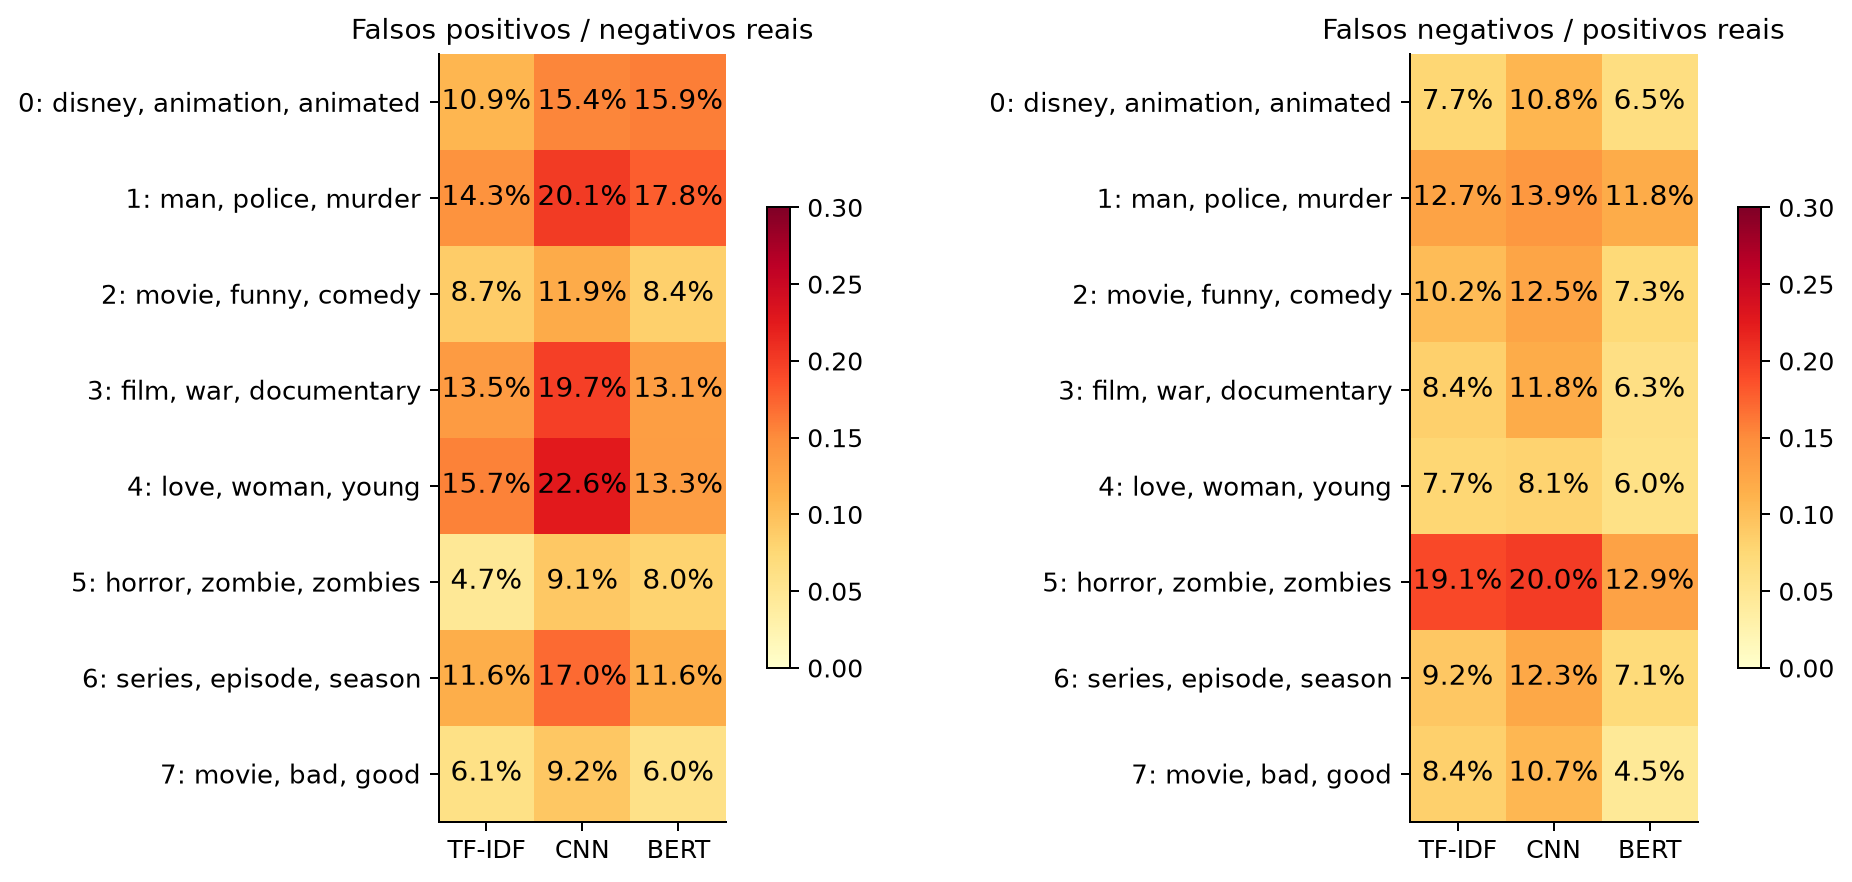

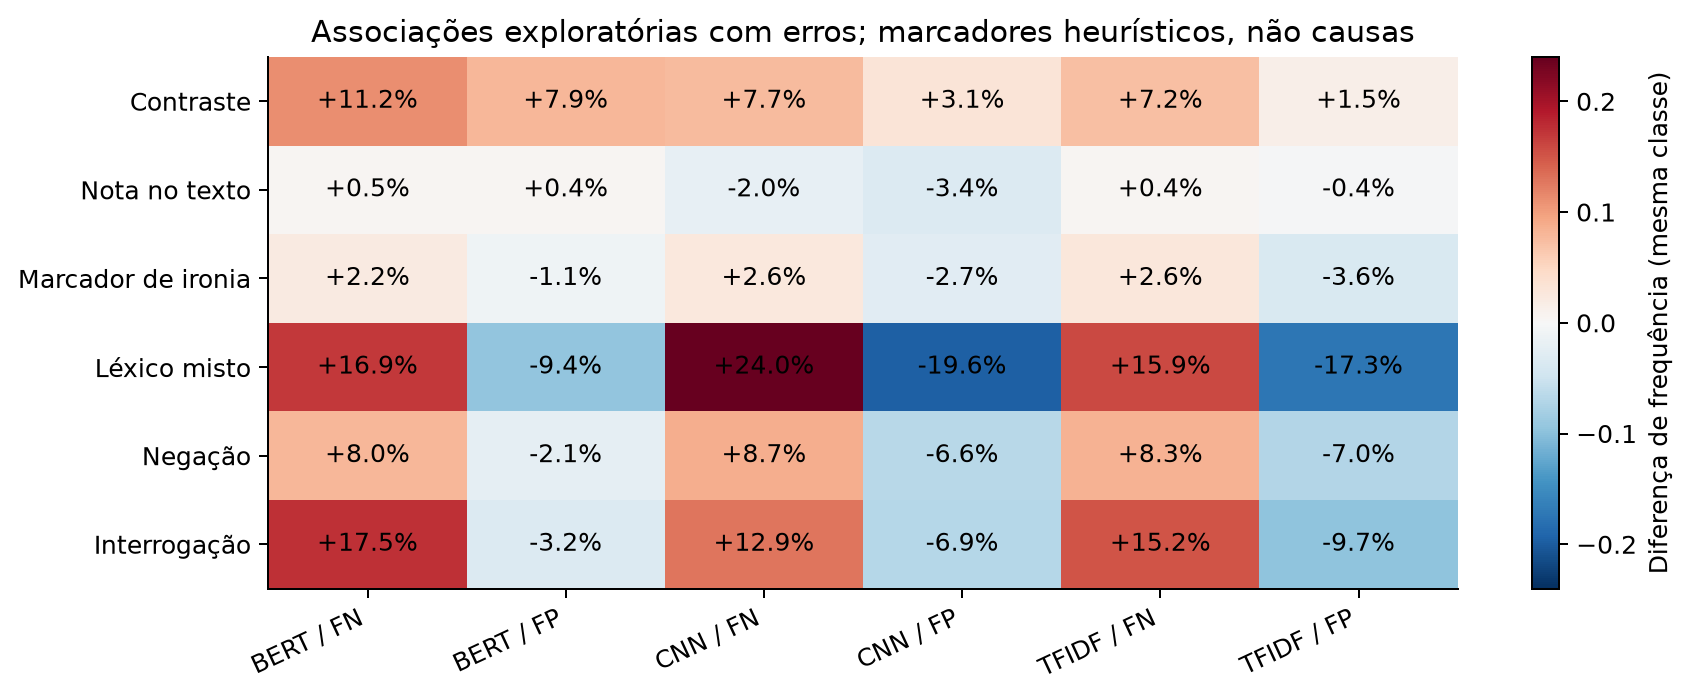

In [8]:
display(read('results/analysis/cluster_terms.json'))
segments = pd.read_csv(ROOT / 'results/analysis/subgroup_metrics.csv')
display(segments.loc[segments.group=='semantic_cluster'])
plot('semantic_error_rates.png')
plot('error_marker_contrasts.png')

## RFM e AGOP

Com $K_M(x,z)=\exp[-\sqrt{(x-z)^TM(x-z)}/L]$, ajusta-se regressão kernel e atualiza-se $M$ pela AGOP: $M_{t+1}=n^{-1}\sum_i\nabla f_t(h_i)\nabla f_t(h_i)^T$. Usa-se o autovetor principal, orientado positivamente pela correlação com o rótulo. **AGOP não é a Hessiana exata.** O experimento adapta [Beaglehole et al.](https://arxiv.org/abs/2502.03708) ao CLS de um encoder classificador.

{'layer': 9,
 'bandwidth': 30.0,
 'validation_auc': 0.9619727766587317,
 'selected_iteration': 1,
 'history': [{'iteration': 1,
   'validation_auc': 0.9619727766587317,
   'validation_mse': 0.0867884159354109,
   'agop_trace': 0.004444772993833012},
  {'iteration': 2,
   'validation_auc': 0.9377403405969602,
   'validation_mse': 0.09409881377079983,
   'agop_trace': 0.010702330379010777},
  {'iteration': 3,
   'validation_auc': 0.904352072270036,
   'validation_mse': 0.10345684681492578,
   'agop_trace': 0.017964146644277083},
  {'iteration': 4,
   'validation_auc': 0.891900140389428,
   'validation_mse': 0.10443491952029132,
   'agop_trace': 0.020472751914737315}]}

AUC da sonda no subconjunto de teste: 0.94976806640625


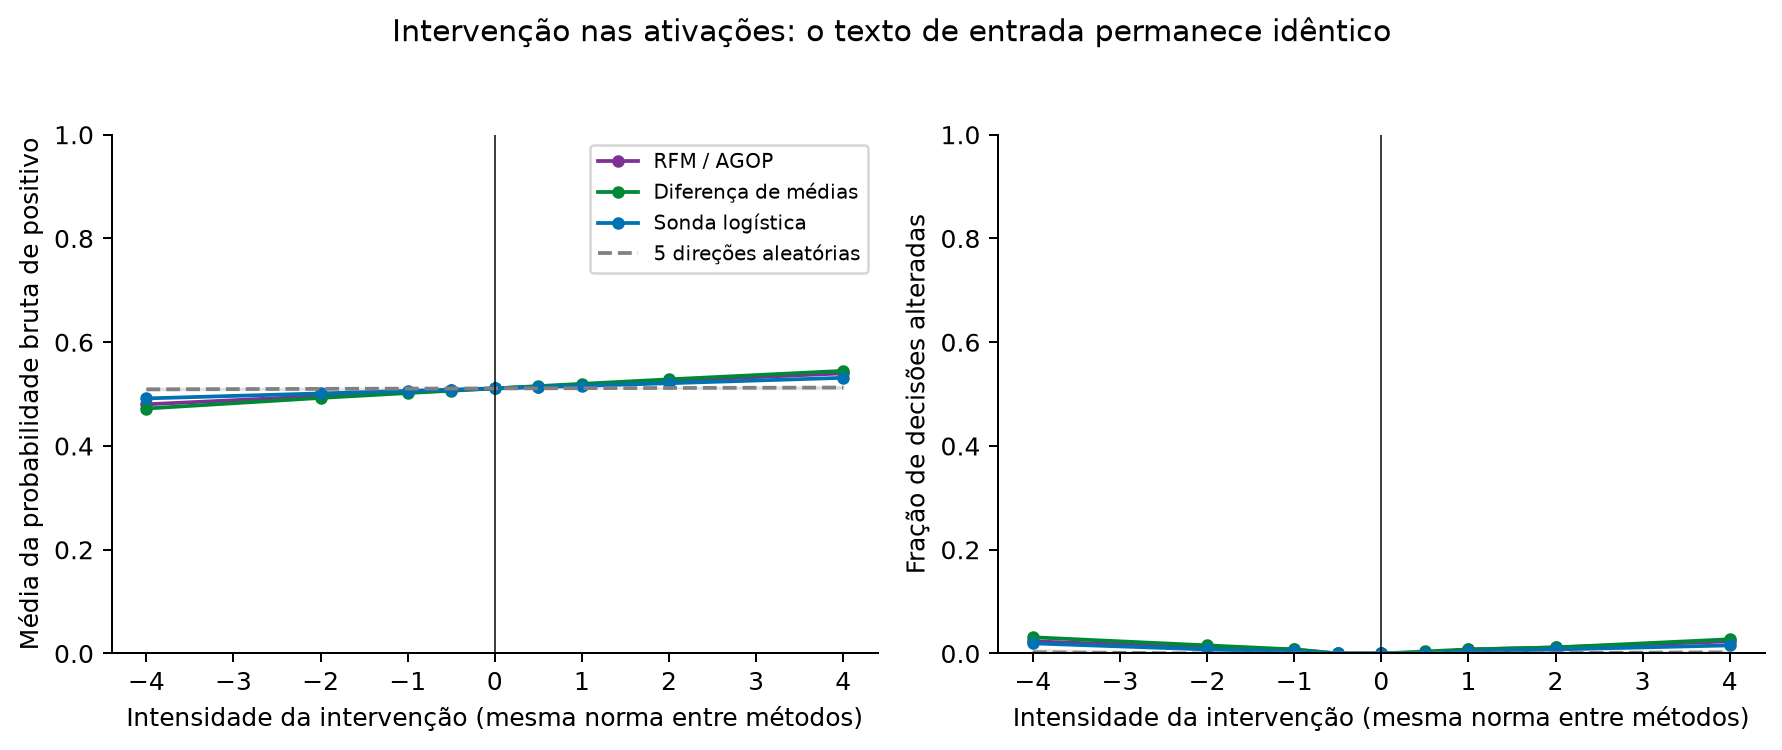

In [9]:
selection = read('results/steering/probe_selection.json')
display(selection['selected'])
print('AUC da sonda no subconjunto de teste:', selection['heldout_test_rfm_auc'])
steering_meta = read('results/steering/metadata.json')
assert steering_meta['hook_restoration_exact']
assert max(steering_meta['zero_alpha_max_logit_difference'].values()) < 2e-5
plot('steering.png')

## Demonstrações neutras e mudança do escore

Sondas sintéticas neutras não constituem uma classe neutra no IMDb. O texto abaixo permanece idêntico; somente a saída do classificador é alterada. Sob intervenção, não se assume que a calibração usual continue válida.

In [10]:
probes = pd.DataFrame(read('results/steering/synthetic_probes.json'))
interventions = pd.read_parquet(ROOT / 'results/steering/interventions.parquet')
view = interventions.loc[(interventions.split=='synthetic') & (interventions.method=='rfm_agop') & interventions.alpha.isin([-4,0,4])]
display(view.merge(probes,on='id')[['id','alpha','clean_text','p_positive_raw','input_text_unchanged']])

,id,alpha,clean_text,p_positive_raw,input_text_unchanged
0,neutral_1,-4.0,The film follows a family moving to a new town...,0.559954,True
1,neutral_2,-4.0,I watched the movie yesterday. The story takes...,0.851747,True
2,neutral_3,-4.0,The movie was ordinary and the acting was aver...,0.014122,True
3,negative_1,-4.0,The acting was terrible and the story was bori...,0.006449,True
4,negative_2,-4.0,"I found the film dull, disappointing and forge...",0.006191,True
5,positive_1,-4.0,The acting was excellent and the story was won...,0.994407,True
6,mixed_1,-4.0,"The actors were excellent, but the story was s...",0.013103,True
7,negation_1,-4.0,"I expected to hate this film, but it was not b...",0.990185,True
8,neutral_1,0.0,The film follows a family moving to a new town...,0.719317,True
9,neutral_2,0.0,I watched the movie yesterday. The story takes...,0.945267,True


## Edição real de palavras com masked LM

Etapa separada para alterar o texto. O encoder coincide com o BERT ajustado. A transformação e o bias da cabeça MLM vêm do pré-treinamento; sua projeção de saída permanece ligada aos embeddings ajustados. Preenchimento sequencial de duas palavras mascaradas, sem reranqueamento por sentimento; todos os resultados e o controle aleatório são preservados. Fluência e sentimento ainda exigem revisão humana.

,id,method,alpha,original,edited,tfidf_edited_p_positive,bert_edited_p_positive,semantic_cosine_to_original
1,neutral_a,rfm_agop,-4,The movie was ordinary and the acting was aver...,the movie was cancelled and the acting was can...,0.350262,0.369034,0.503853
3,neutral_a,rfm_agop,0,The movie was ordinary and the acting was aver...,the movie was successful and the acting was pr...,0.095771,0.904831,0.538209
5,neutral_a,rfm_agop,4,The movie was ordinary and the acting was aver...,the movie was successful and the acting was ex...,0.894311,0.907476,0.633747
8,neutral_a,random_1,-4,The movie was ordinary and the acting was aver...,the movie was successful and the acting was su...,0.085849,0.833523,0.583570
10,neutral_a,random_1,0,The movie was ordinary and the acting was aver...,the movie was successful and the acting was pr...,0.095771,0.904831,0.538209
12,neutral_a,random_1,4,The movie was ordinary and the acting was aver...,the movie was praised and the acting was praised.,0.084722,0.925740,0.504627
15,neutral_b,rfm_agop,-4,The story was simple and the ending was predic...,the story was cut and the ending was cut.,0.591614,0.316786,0.670056
17,neutral_b,rfm_agop,0,The story was simple and the ending was predic...,the story was changed and the ending was changed.,0.695884,0.534243,0.670663
19,neutral_b,rfm_agop,4,The story was simple and the ending was predic...,the story was released and the ending was rele...,0.792161,0.755117,0.644019
22,neutral_b,random_1,-4,The story was simple and the ending was predic...,the story was cancelled and the ending was can...,0.798628,0.448643,0.604079


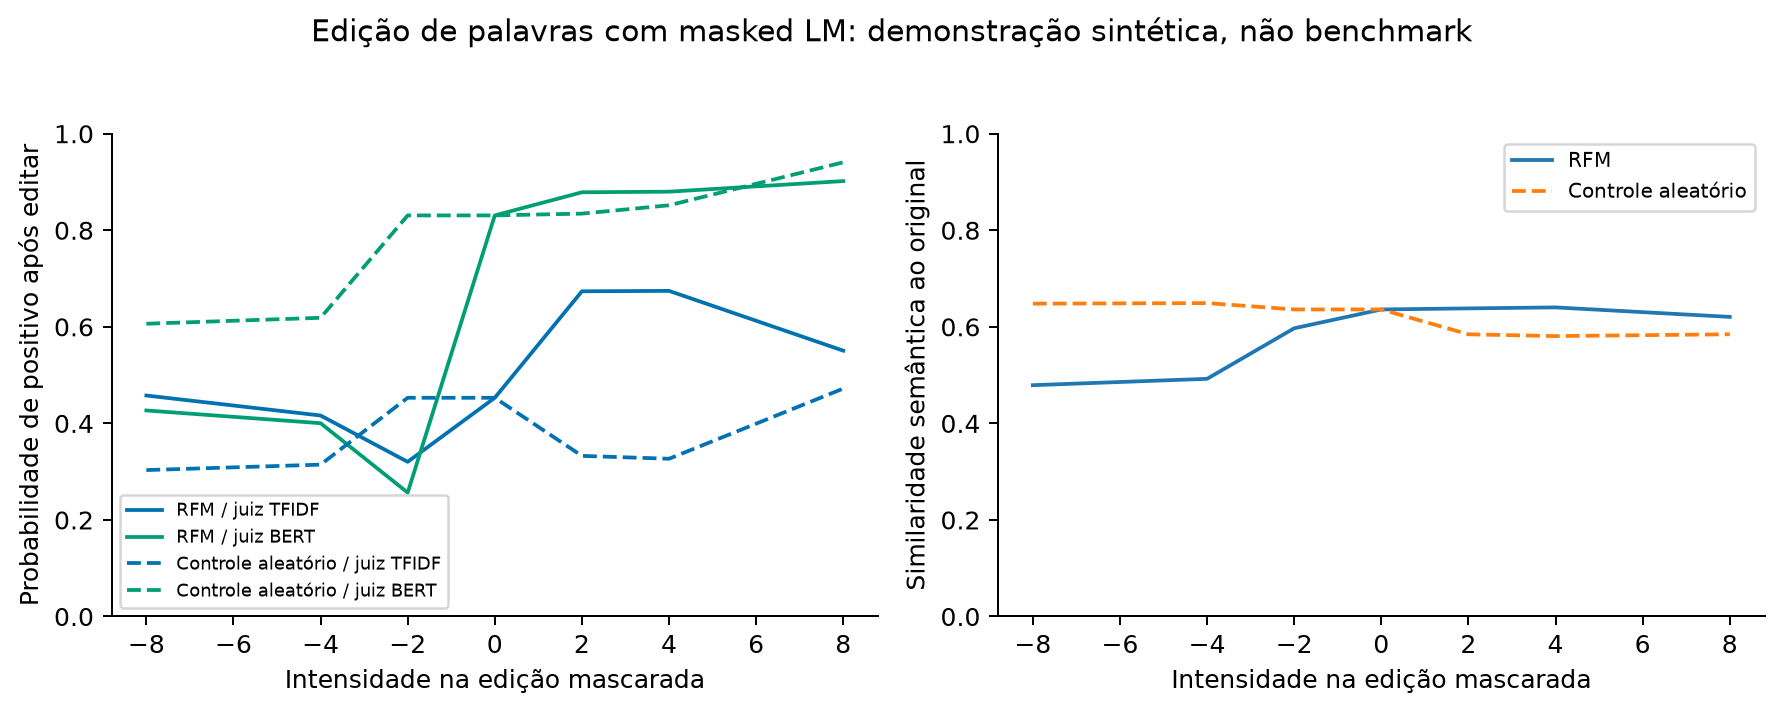

In [11]:
edits = pd.DataFrame(read('results/rewrite/examples.json'))
display(edits.loc[edits.alpha.isin([-4,0,4]), ['id','method','alpha','original','edited','tfidf_edited_p_positive','bert_edited_p_positive','semantic_cosine_to_original']])
plot('text_editing.png')

## Quando o modelo de aprendizagem profunda falha?

Investigue negação, mistura de opiniões, ironia, descrição do enredo e truncamento. Não atribua causalidade somente a marcadores. Limitações: uma semente, orçamentos de entrada distintos, notas polarizadas, teste com repetições internas e amostra pequena no steering. Alterar o escore pode revelar fragilidade; não demonstra melhora na compreensão.

## Reproduzir treinos

O comando abaixo baixa os dados públicos, refaz as divisões, treina, avalia, analisa e gera os arquivos. Exige tempo e memória. Também é possível executar cada etapa: `prepare`, `baseline`, `cnn`, `bert`, `analyze`, `steer`, `rewrite`, `report`. Veja README e configuração.

In [12]:
RUN_TRAINING = False
if RUN_TRAINING:
    import subprocess
    subprocess.run([sys.executable, str(ROOT/'run.py'), 'all'], cwd=ROOT, check=True)
else:
    print('Leitura dos resultados concluída; treino não repetido.')

Leitura dos resultados concluída; treino não repetido.
